# BUSINESS ANALYTICS - GROUP ASSIGNMENT

Digital Ads Data | ads24x7  

Segmenting ad types into homogeneous groups using Clustering  


## Step 1 : Importing the libraries


In [20]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [22]:
import warnings
warnings.filterwarnings('ignore')

## Step 2 : Reading the data and basic analysis


In [23]:
df = pd.read_excel('Clustering Clean Ads_Data.xlsx')
df.head()

,Timestamp,InventoryType,Ad - Length,Ad- Width,Ad Size,Ad Type,Platform,Device Type,Format,Available_Impressions,Matched_Queries,Impressions,Clicks,Spend,Fee,Revenue,CTR,CPM,CPC
0,2020-9-2-17,Format1,300,250,75000,Inter222,Video,Desktop,Display,1806,325,323,1,0.0,0.35,0.0,0.0031,0.0,0.0
1,2020-9-2-18,Format1,300,250,75000,Inter223,Web,Mobile,Display,1979,384,380,0,0.0,0.35,0.0,0.0000,0.0,NaN
2,2020-9-3-16,Format6,336,250,84000,Inter217,Web,Desktop,Video,1566,298,297,0,0.0,0.35,0.0,0.0000,0.0,NaN
3,2020-9-3-2,Format1,300,250,75000,Inter224,Web,Desktop,Display,643,103,102,0,0.0,0.35,0.0,0.0000,0.0,NaN
4,2020-9-3-13,Format1,300,250,75000,Inter225,Video,Mobile,Display,1550,347,345,0,0.0,0.35,0.0,0.0000,0.0,NaN


In [24]:
# The data set imported above is a digital advertising data set. It contains the
# performance of ads served by ads24x7 across different devices, platforms and formats.

# Let us look at the last few records as well.
df.tail()

,Timestamp,InventoryType,Ad - Length,Ad- Width,Ad Size,Ad Type,Platform,Device Type,Format,Available_Impressions,Matched_Queries,Impressions,Clicks,Spend,Fee,Revenue,CTR,CPM,CPC
25852,2020-10-1-5,Format5,720,300,216000,Inter222,Video,Desktop,Video,1,1,1,0,0.01,0.35,0.0065,NaN,NaN,NaN
25853,2020-11-18-2,Format4,120,600,72000,inter230,Video,Mobile,Video,7,1,1,1,0.07,0.35,0.0455,NaN,NaN,NaN
25854,2020-9-14-0,Format5,720,300,216000,Inter221,App,Mobile,Video,2,2,2,1,0.09,0.35,0.0585,NaN,NaN,NaN
25855,2020-9-30-4,Format7,300,600,180000,Inter228,Video,Mobile,Display,1,1,1,0,0.01,0.35,0.0065,NaN,NaN,NaN
25856,2020-10-17-3,Format5,720,300,216000,Inter225,Video,Mobile,Display,1,1,1,0,0.01,0.35,0.0065,NaN,NaN,NaN


In [25]:
# Checking the shape of the data
print('Number of rows :', df.shape[0])
print('Number of columns :', df.shape[1])

Number of rows : 25857
Number of columns : 19


In [26]:
# The info function gives us the data types and the non-null counts of every column
df.info()

# FINDING : CTR, CPM and CPC have fewer non-null values than the other columns.
# So these three columns are the ones carrying missing values.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25857 entries, 0 to 25856
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Timestamp              25857 non-null  object 
 1   InventoryType          25857 non-null  object 
 2   Ad - Length            25857 non-null  int64  
 3   Ad- Width              25857 non-null  int64  
 4   Ad Size                25857 non-null  int64  
 5   Ad Type                25857 non-null  object 
 6   Platform               25857 non-null  object 
 7   Device Type            25857 non-null  object 
 8   Format                 25857 non-null  object 
 9   Available_Impressions  25857 non-null  int64  
 10  Matched_Queries        25857 non-null  int64  
 11  Impressions            25857 non-null  int64  
 12  Clicks                 25857 non-null  int64  
 13  Spend                  25857 non-null  float64
 14  Fee                    25857 non-null  float64
 15  Re

In [27]:
# The 'describe' function gives us the five point summary of the numerical variables
df.describe().T

# FINDING : Impressions, Clicks and Spend have a very large range compared to
# CTR, CPM and CPC. This tells us that scaling will be needed before clustering.

,count,mean,std,min,25%,50%,75%,max
Ad - Length,25857.0,3.904312e+02,2.306961e+02,120.00,120.0000,300.0000,7.200000e+02,728.00
Ad- Width,25857.0,3.321828e+02,1.942609e+02,70.00,250.0000,300.0000,6.000000e+02,600.00
Ad Size,25857.0,9.968328e+04,6.264069e+04,33600.00,72000.0000,75000.0000,8.400000e+04,216000.00
Available_Impressions,25857.0,2.169621e+06,4.542680e+06,0.00,9133.0000,330968.0000,2.208484e+06,27592861.00
Matched_Queries,25857.0,1.155322e+06,2.407244e+06,0.00,5451.0000,189449.0000,1.008171e+06,14702025.00
Impressions,25857.0,1.107525e+06,2.326648e+06,0.00,2558.0000,162162.0000,9.496930e+05,14194774.00
Clicks,25857.0,9.525881e+03,1.672169e+04,0.00,305.0000,3457.0000,1.068100e+04,143049.00
Spend,25857.0,2.414473e+03,3.932835e+03,0.00,36.0300,1173.6600,2.692280e+03,26931.87
Fee,25857.0,3.367289e-01,3.053978e-02,0.21,0.3500,0.3500,3.500000e-01,0.35
Revenue,25857.0,1.716549e+03,2.993025e+03,0.00,23.4200,762.8800,1.749982e+03,21276.18


In [28]:
# Let us now check the null values in every column
df.isnull().sum()

# FINDING : CTR has 6465 nulls, CPM has 6465 nulls and CPC has 7527 nulls
# Everything else is complete

,0
Timestamp,0
InventoryType,0
Ad - Length,0
Ad- Width,0
Ad Size,0
Ad Type,0
Platform,0
Device Type,0
Format,0
Available_Impressions,0


In [29]:
# Let us check the duplicate records in the data
print('Number of duplicate rows :', df.duplicated().sum())

# FINDING : There are no duplicate records, so no row needs to be dropped

Number of duplicate rows : 0


In [30]:
# Checking the categorical variables present in the data
for col in ['InventoryType', 'Ad Type', 'Platform', 'Device Type', 'Format']:
    print(col, ':', df[col].nunique(), 'levels ->', list(df[col].unique()))

InventoryType : 7 levels -> ['Format1', 'Format6', 'Format5', 'Format7', 'Format4', 'Format3', 'Format2']
Ad Type : 14 levels -> ['Inter222', 'Inter223', 'Inter217', 'Inter224', 'Inter225', 'Inter226', 'Inter227', 'Inter228', 'Inter218', 'Inter219', 'inter230', 'Inter220', 'Inter221', 'Inter229']
Platform : 3 levels -> ['Video', 'Web', 'App']
Device Type : 2 levels -> ['Desktop', 'Mobile']
Format : 2 levels -> ['Display', 'Video']


In [31]:
# Some sanity checks on the business logic of the data
print('Rows where Impressions are zero :', (df['Impressions'] == 0).sum())
print('Rows where Clicks are zero :', (df['Clicks'] == 0).sum())
print('Rows where Clicks are more than Impressions :', (df['Clicks'] > df['Impressions']).sum())

# FINDING : 219 rows have 0 Impressions and 2791 rows have 0 Clicks. These are ads
# that were served but got no traction. One single row has Clicks greater than Impressions,
# which is not possible in reality and is a data entry error.

Rows where Impressions are zero : 219
Rows where Clicks are zero : 2791
Rows where Clicks are more than Impressions : 1


## Step 3 : Treating the missing values using user defined functions


In [32]:
# The assignment gives us the three standard digital marketing formulas :
#     CPM = (Total Campaign Spend / Number of Impressions) * 1000
#     CPC = Total Cost (Spend) / Number of Clicks
#     CTR = (Total Measured Clicks / Total Measured Ad Impressions) * 100
#
# NOTE ON CTR : The CTR values already present in the file are stored as a plain ratio
# and not as a percentage. For example, 1 click on 323 impressions is stored as 0.0031
# instead of 0.31. The assignment formula asks for a percentage. So we multiply the
# already present values by 100 as well, otherwise the imputed values and the original
# values would sit on two different scales inside the same column.

def impute_ctr(row):
    # CTR = (Clicks / Impressions) * 100
    # If Impressions are 0 we return 0 to avoid dividing by 0.
    if pd.isnull(row['CTR']):
        if row['Impressions'] == 0:
            return 0.0
        return round((row['Clicks'] / row['Impressions']) * 100, 4)
    return round(row['CTR'] * 100, 4)

In [1]:
def impute_cpm(row):
    # CPM = (Spend / Impressions) * 1000
    # If Impressions are zero we return 0.
    if pd.isnull(row['CPM']):
        if row['Impressions'] == 0:
            return 0.0
        return round((row['Spend'] / row['Impressions']) * 1000, 2)
    return row['CPM']

In [34]:
def impute_cpc(row):
    # CPC = Spend / Clicks
    # If Clicks are zero we return 0, because the ad was served but nobody clicked
    # so there is no cost per click to speak of.
    if pd.isnull(row['CPC']):
        if row['Clicks'] == 0:
            return 0.0
        return round(row['Spend'] / row['Clicks'], 2)
    return row['CPC']

In [35]:
# Now let us call the three functions and impute the columns
df['CTR'] = df.apply(impute_ctr, axis=1)
df['CPM'] = df.apply(impute_cpm, axis=1)
df['CPC'] = df.apply(impute_cpc, axis=1)

In [36]:
# Checking the null values once again after imputation.
df.isnull().sum()

# FINDING : All the missing values are now filled. No column has nulls left.

,0
Timestamp,0
InventoryType,0
Ad - Length,0
Ad- Width,0
Ad Size,0
Ad Type,0
Platform,0
Device Type,0
Format,0
Available_Impressions,0


In [37]:
df[['CTR', 'CPM', 'CPC']].describe().T

,count,mean,std,min,25%,50%,75%,max
CTR,25857.0,7.502185,9.128851,0.0,0.23,0.72,13.06,200.00
CPM,25857.0,7.524721,8.927584,0.0,1.57,2.96,12.45,715.00
CPC,25857.0,0.300301,0.338797,0.0,0.08,0.12,0.50,7.26


## Step 4 : Checking for outliers


In [38]:
# We will build the clusters on CTR, CPM and CPC, so we check the outliers on these three.
data = df[['CTR', 'CPM', 'CPC']]

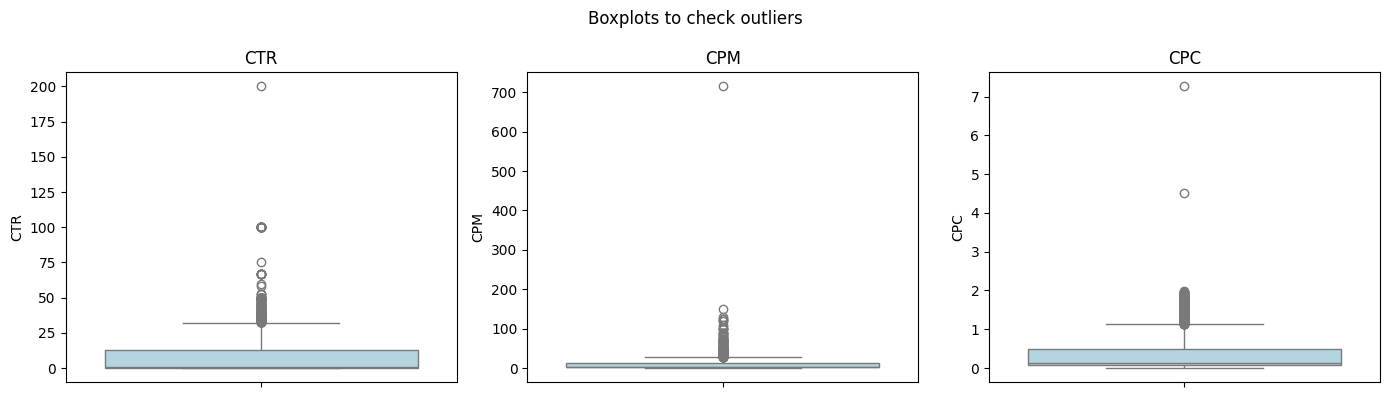

In [39]:
plt.figure(figsize=(14, 4))
for i, col in enumerate(data.columns):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=data[col], color='lightblue')
    plt.title(col)
plt.suptitle('Boxplots to check outliers')
plt.tight_layout()
plt.show()

In [40]:
# Let us also count the outliers using the IQR rule.
for col in data.columns:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((data[col] < lower) | (data[col] > upper)).sum()
    print(col, ': lower =', round(lower, 3), ', upper =', round(upper, 3),
          ', outliers =', count, '(', round(count / len(data) * 100, 2), '% )')

# FINDING : CTR has around 1.2% outliers, CPM has around 0.9% and CPC has around 2.7%.
# The outliers are on the higher side in all three columns.

CTR : lower = -19.015 , upper = 32.305 , outliers = 302 ( 1.17 % )
CPM : lower = -14.75 , upper = 28.77 , outliers = 229 ( 0.89 % )
CPC : lower = -0.55 , upper = 1.13 , outliers = 709 ( 2.74 % )


## Step 5 : Treating the outliers


In [41]:
# Is outlier treatment necessary for K-Means?
# Yes. K-Means works on Euclidean distance and it puts every point into the cluster
# whose centroid is nearest. A centroid is nothing but a mean, and a mean gets dragged
# by extreme values. So a handful of very high CPM or CPC records can pull a centroid
# away from the rest of the group and we end up with a cluster that is built around
# noise instead of a real segment.
#
# Which method do we use?
# We are capping the values at the 99th percentile instead of deleting the rows.
# Deleting would throw away genuine premium ad slots, and we would also lose those rows
# from the final segmentation, which the business actually needs. Capping keeps all
# 25857 records and keeps the ordering of the values intact.
# Another analyst may choose to take a log transform instead, which is also acceptable.

for col in ['CTR', 'CPM', 'CPC']:
    cap = df[col].quantile(0.99)
    df[col] = df[col].clip(upper=cap)
    print(col, 'capped at', round(cap, 3))

CTR capped at 33.333
CPM capped at 27.664
CPC capped at 1.48


In [42]:
# Let us check the boxplots once again after treatment.
data = df[['CTR', 'CPM', 'CPC']]

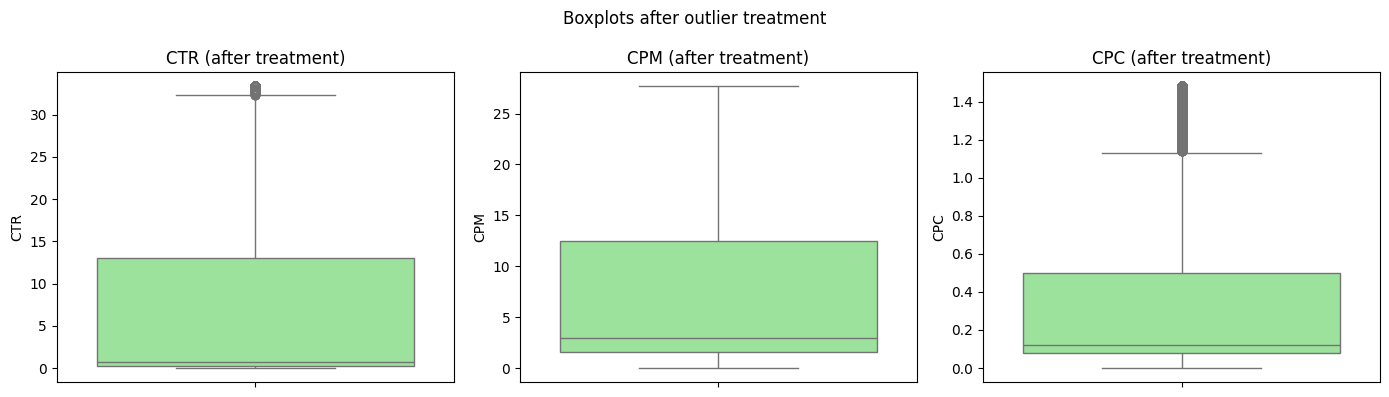

In [43]:
plt.figure(figsize=(14, 4))
for i, col in enumerate(data.columns):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=data[col], color='lightgreen')
    plt.title(col + ' (after treatment)')
plt.suptitle('Boxplots after outlier treatment')
plt.tight_layout()
plt.show()

In [44]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
CTR,25857.0,7.336181,8.204192,0.0,0.23,0.72,13.06,33.3333
CPM,25857.0,7.345780,6.899836,0.0,1.57,2.96,12.45,27.6644
CPC,25857.0,0.298408,0.329068,0.0,0.08,0.12,0.50,1.4800


## Step 6 : Z-score scaling


In [45]:
# z = (x - mean) / standard deviation
#
# Why do we scale?
# CTR is a percentage, CPM is a cost/thousand impressions and CPC is a cost per
# single click. All three sit on completely different ranges. If we do not scale,
# the variable with the biggest numbers decides the distance almost by itself and the
# other two barely matter.
#
# How does it affect the speed of the algorithm?
# After scaling, all three variables sit inside a small and roughly symmetric range
# around zero. The centroids therefore start close to the data and stop moving after
# fewer passes, so K-Means converges in fewer iterations. On unscaled data the
# centroids have to travel much longer distances before they settle.

scale = StandardScaler()

In [46]:
data_scaled = pd.DataFrame(scale.fit_transform(data), columns=data.columns)
data_scaled.head()

,CTR,CPM,CPC
0,-0.856430,-1.064652,-0.906845
1,-0.894216,-1.064652,-0.906845
2,-0.894216,-1.064652,-0.906845
3,-0.894216,-1.064652,-0.906845
4,-0.894216,-1.064652,-0.906845


In [47]:
# Let us confirm that the mean is 0 and the standard deviation is 1 after scaling.
data_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
CTR,25857.0,-8.793506e-17,1.000019,-0.894216,-0.866181,-0.806455,0.697684,3.168822
CPM,25857.0,1.582831e-16,1.000019,-1.064652,-0.837106,-0.635648,0.739774,2.944855
CPC,25857.0,7.474480e-17,1.000019,-0.906845,-0.663730,-0.542172,0.612628,3.590796


## Step 7 : Hierarchical clustering - dendrogram using ward and euclidean distance


In [48]:
# NOTE : This data set has 25857 records. Hierarchical clustering has to compute the
# distance between every possible pair of records, which comes to roughly 334 million
# pairs and needs several GB of memory. It also makes the dendrogram completely
# unreadable. So we draw the dendrogram on a random sample of 2000 records, which is
# enough to see where the natural cuts are.

np.random.seed(42)
sample_index = np.random.choice(data_scaled.index, size=2000, replace=False)
data_sample = data_scaled.loc[sample_index]

In [49]:
# Building the linkage matrix using Ward's method and Euclidean distance
wardlink = linkage(data_sample, method='ward', metric='euclidean')

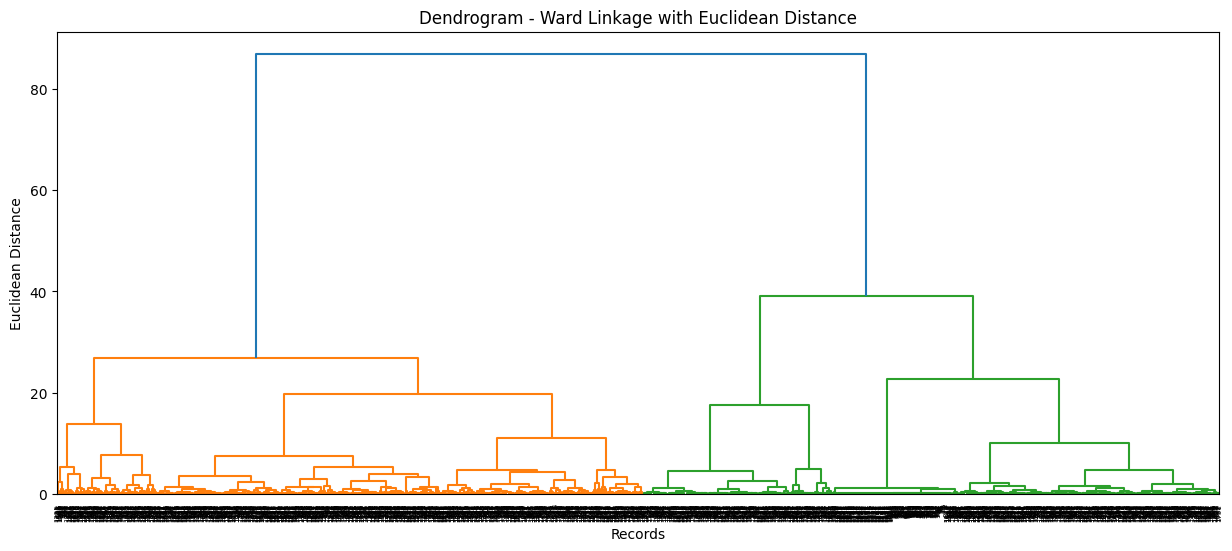

In [50]:
# Plotting the full dendrogram
plt.figure(figsize=(15, 6))
warddend = dendrogram(wardlink)
plt.title('Dendrogram - Ward Linkage with Euclidean Distance')
plt.xlabel('Records')
plt.ylabel('Euclidean Distance')
plt.show()

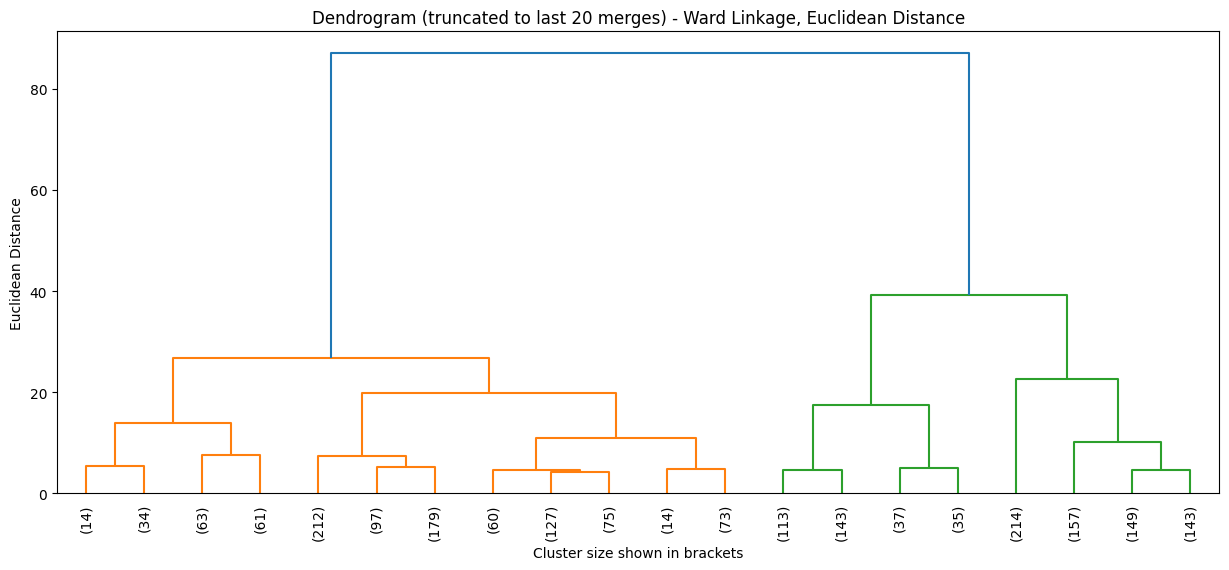

In [51]:
# The above dendrogram is still crowded because of the number of records. So let us
# truncate it and show only the last 20 merges, which is where the decision is made.
#
# NOTE : show_contracted = True makes scipy walk down every
# collapsed branch using a recursive function, and on a data set of this size it crosses
# Python's recursion limit and throws a RecursionError.

plt.figure(figsize=(15, 6))
warddend = dendrogram(wardlink,
                      truncate_mode='lastp',
                      p=20,
                      leaf_rotation=90,
                      leaf_font_size=10)
plt.title('Dendrogram (truncated to last 20 merges) - Ward Linkage, Euclidean Distance')
plt.xlabel('Cluster size shown in brackets')
plt.ylabel('Euclidean Distance')
plt.show()

# FINDING : The longest vertical lines that are not cut by any horizontal merge sit
# in the region that separates 3 to 4 groups. So the dendrogram supports a solution
# somewhere around 3 or 4 clusters.

In [52]:
# Let us extract the clusters from the dendrogram using the maxclust criterion.
clusters = fcluster(wardlink, 4, criterion='maxclust')
print('Cluster labels from hierarchical clustering :', np.unique(clusters))
print(pd.Series(clusters).value_counts().sort_index())

# NOTE : fcluster already numbers the clusters starting from 1

Cluster labels from hierarchical clustering : [1 2 3 4]
1    172
2    837
3    328
4    663
Name: count, dtype: int64


## Step 8 : K-MEANS - ELBOW PLOT UP TO n = 10


In [53]:
# We do not know the value of 'K' beforehand, so we run K-Means for different values
# of K and record the Within Sum of Squares (WSS) each time. In sklearn the WSS is
# stored in the 'inertia_' attribute.

wss = []

In [54]:
for i in range(1, 11):
    KM = KMeans(n_clusters=i, random_state=42, n_init=10)
    KM.fit(data_scaled)
    wss.append(KM.inertia_)

In [55]:
# Printing the WSS values.
for i in range(1, 11):
    print('The WSS value for', i, 'clusters is', round(wss[i - 1], 2))

The WSS value for 1 clusters is 77571.0
The WSS value for 2 clusters is 28609.73
The WSS value for 3 clusters is 17906.8
The WSS value for 4 clusters is 12464.82
The WSS value for 5 clusters is 9436.78
The WSS value for 6 clusters is 7354.74
The WSS value for 7 clusters is 5601.83
The WSS value for 8 clusters is 4454.14
The WSS value for 9 clusters is 3797.3
The WSS value for 10 clusters is 3278.08


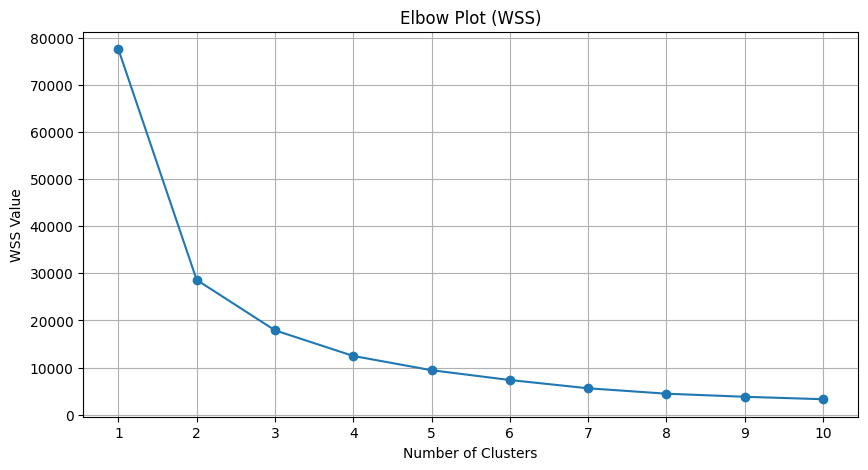

In [56]:
# Plotting the elbow curve.
plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wss, marker='o')
plt.grid()
plt.title('Elbow Plot (WSS)')
plt.xlabel('Number of Clusters')
plt.ylabel('WSS Value')
plt.xticks(range(1, 11))
plt.show()

In [57]:
# Let us also look at how much the WSS drops at every step, which makes the elbow
# easier to read than the curve alone.
for i in range(1, 10):
    drop = (wss[i - 1] - wss[i]) / wss[i - 1] * 100
    print('Going from', i, 'to', i + 1, 'clusters reduces WSS by', round(drop, 1), '%')

# FINDING : The drop is 63% from 1 to 2, 37% from 2 to 3 and 30% from 3 to 4. After
# 4 clusters the reduction falls to around 24% and keeps flattening. So the bend in
# the curve is around K = 4.

Going from 1 to 2 clusters reduces WSS by 63.1 %
Going from 2 to 3 clusters reduces WSS by 37.4 %
Going from 3 to 4 clusters reduces WSS by 30.4 %
Going from 4 to 5 clusters reduces WSS by 24.3 %
Going from 5 to 6 clusters reduces WSS by 22.1 %
Going from 6 to 7 clusters reduces WSS by 23.8 %
Going from 7 to 8 clusters reduces WSS by 20.5 %
Going from 8 to 9 clusters reduces WSS by 14.7 %
Going from 9 to 10 clusters reduces WSS by 13.7 %


## Step 9 : Silhouette scores up to 10 clusters


In [58]:
# The silhouette score tells us how well a record sits inside its own cluster compared
# to the nearest neighbouring cluster. It ranges from -1 to +1 and higher is better.
#
# NOTE : the silhouette score needs the distance between every pair of records, which is
# slow on 25857 rows. We therefore pass sample_size = 5000 so that sklearn computes the
# score on a random subset. We checked this against the full calculation and the scores
# matched to within 0.005, while running about 20 times faster.

sil_scores = []

In [59]:
for i in range(2, 11):
    KM = KMeans(n_clusters=i, random_state=42, n_init=10)
    labels = KM.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, labels, sample_size=5000, random_state=42)
    sil_scores.append(score)

In [60]:
# Printing the silhouette scores.
for i in range(2, 11):
    print('The silhouette score for', i, 'clusters is', round(sil_scores[i - 2], 4))

The silhouette score for 2 clusters is 0.6014
The silhouette score for 3 clusters is 0.5586
The silhouette score for 4 clusters is 0.5109
The silhouette score for 5 clusters is 0.5185
The silhouette score for 6 clusters is 0.4914
The silhouette score for 7 clusters is 0.5249
The silhouette score for 8 clusters is 0.5448
The silhouette score for 9 clusters is 0.5085
The silhouette score for 10 clusters is 0.5057


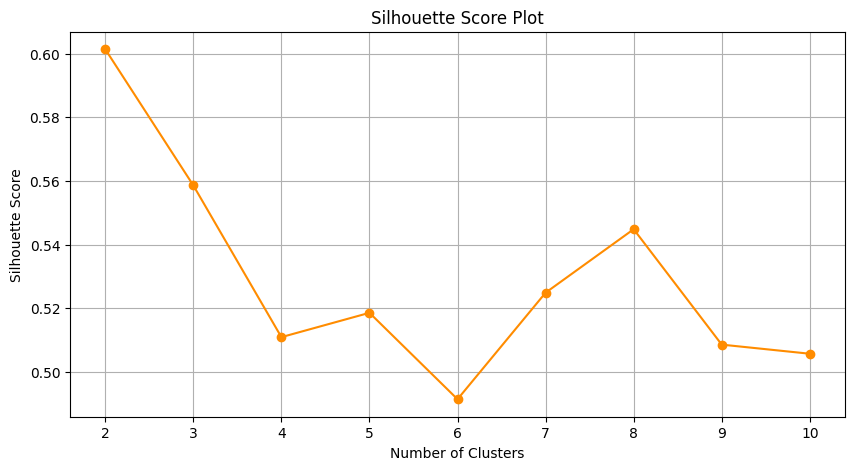

In [61]:
# Plotting the silhouette scores.
plt.figure(figsize=(10, 5))
plt.plot(range(2, 11), sil_scores, marker='o', color='darkorange')
plt.grid()
plt.title('Silhouette Score Plot')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.show()

# FINDING : The highest silhouette score comes at K = 2. But a two cluster solution only
# splits the ads into 'got some traction' and 'got almost none', which is not useful to
# a marketing team. K = 4 keeps a healthy score of about 0.51, matches the bend in the
# elbow plot and matches the cut in the dendrogram. We are therefore going ahead with
# 4 clusters. The full reasoning is written up in the inference document.

## Step 10 : Building the final k-means model with 4 clusters


In [62]:
k_means = KMeans(n_clusters=4, random_state=42, n_init=10)
k_means.fit(data_scaled)

KMeans(n_clusters=4, n_init=10, random_state=42)

In [63]:
labels = k_means.labels_

In [64]:
# sklearn numbers the clusters starting from 0. We add 1 so that the clusters are
# numbered 1, 2, 3 and 4, which reads better in the report and also matches the
# numbering that fcluster gives in hierarchical clustering.
df['Clusters'] = labels + 1

In [65]:
df.head()

,Timestamp,InventoryType,Ad - Length,Ad- Width,Ad Size,Ad Type,Platform,Device Type,Format,Available_Impressions,Matched_Queries,Impressions,Clicks,Spend,Fee,Revenue,CTR,CPM,CPC,Clusters
0,2020-9-2-17,Format1,300,250,75000,Inter222,Video,Desktop,Display,1806,325,323,1,0.0,0.35,0.0,0.31,0.0,0.0,3
1,2020-9-2-18,Format1,300,250,75000,Inter223,Web,Mobile,Display,1979,384,380,0,0.0,0.35,0.0,0.00,0.0,0.0,3
2,2020-9-3-16,Format6,336,250,84000,Inter217,Web,Desktop,Video,1566,298,297,0,0.0,0.35,0.0,0.00,0.0,0.0,3
3,2020-9-3-2,Format1,300,250,75000,Inter224,Web,Desktop,Display,643,103,102,0,0.0,0.35,0.0,0.00,0.0,0.0,3
4,2020-9-3-13,Format1,300,250,75000,Inter225,Video,Mobile,Display,1550,347,345,0,0.0,0.35,0.0,0.00,0.0,0.0,3


In [66]:
# Checking how many records fall into each cluster.
cluster_freq = df['Clusters'].value_counts().sort_index()
print(cluster_freq)

Clusters
1    6663
2    3400
3    6528
4    9266
Name: count, dtype: int64


In [67]:
# Exporting the data along with the cluster labels.
df.to_csv('KMeans_Ads_Output.csv', index=False)

## Step 11 : Cluster profiling


In [68]:
# Profiling using the MEAN of every metric.
df1 = df[['Clicks', 'Spend', 'Revenue', 'CPM', 'CTR', 'CPC', 'Impressions', 'Clusters']]

In [69]:
df_clust = df1.groupby('Clusters').mean()
df_clust = df_clust.reset_index()
df_clust['Frequency'] = cluster_freq.values
round(df_clust, 2)

,Clusters,Clicks,Spend,Revenue,CPM,CTR,CPC,Impressions,Frequency
0,1,7251.86,5744.28,4186.42,1.75,0.24,0.78,3474171.21,6663
1,2,8796.49,1125.81,784.35,18.68,21.14,0.10,57726.68,3400
2,3,2724.46,950.44,625.89,1.08,0.33,0.19,632048.58,6528
3,4,16220.40,1524.36,1050.94,11.63,12.31,0.10,125900.61,9266


In [70]:
# Profiling using the SUM of every metric, which shows the total business contribution
# of each cluster rather than the per ad average.
df_clust_sum = df1.groupby('Clusters').sum().reset_index()
round(df_clust_sum, 0)

,Clusters,Clicks,Spend,Revenue,CPM,CTR,CPC,Impressions
0,1,48319116,38274117.0,27894132.0,11668.0,1585.0,5217.0,23148402751
1,2,29908078,3827742.0,2666801.0,63513.0,71874.0,337.0,196270703
2,3,17785304,6204460.0,4085820.0,7041.0,2130.0,1251.0,4126013154
3,4,150298217,14124712.0,9738053.0,107718.0,114102.0,910.0,1166595064


In [71]:
# Share of the total business contributed by each cluster.
rev_share = df.groupby('Clusters')['Revenue'].sum() / df['Revenue'].sum() * 100
spend_share = df.groupby('Clusters')['Spend'].sum() / df['Spend'].sum() * 100
imp_share = df.groupby('Clusters')['Impressions'].sum() / df['Impressions'].sum() * 100
click_share = df.groupby('Clusters')['Clicks'].sum() / df['Clicks'].sum() * 100

In [72]:
share = pd.DataFrame({'Revenue Share %': round(rev_share, 1),
                      'Spend Share %': round(spend_share, 1),
                      'Impression Share %': round(imp_share, 1),
                      'Click Share %': round(click_share, 1)})
print(share)

          Revenue Share %  Spend Share %  Impression Share %  Click Share %
Clusters                                                                   
1                    62.8           61.3                80.8           19.6
2                     6.0            6.1                 0.7           12.1
3                     9.2            9.9                14.4            7.2
4                    21.9           22.6                 4.1           61.0


In [73]:
# NOTE : Revenue in this data set is simply Spend net of the platform Fee, that is
# Revenue = Spend * (1 - Fee). We verified this on the raw columns. So the ratio of
# Revenue to Spend only reflects the fee slab that was charged and it is NOT a measure
# of how well the ad performed. We have deliberately not reported it as a return figure.
print('\nAverage Fee charged in each cluster :')
print(round(df.groupby('Clusters')['Fee'].mean(), 4))


Average Fee charged in each cluster :
Clusters
1    0.3147
2    0.3427
3    0.3483
4    0.3422
Name: Fee, dtype: float64


In [74]:
# The blended cost per click for the cluster as a whole is a fairer efficiency measure
# than the average of the per ad CPC values, because it weights bigger ads more.
blended_cpc = df.groupby('Clusters')['Spend'].sum() / df.groupby('Clusters')['Clicks'].sum()
print('\nBlended cost per click by cluster :')
print(round(blended_cpc, 4))


Blended cost per click by cluster :
Clusters
1    0.7921
2    0.1280
3    0.3489
4    0.0940
dtype: float64


In [75]:
# Profiling by DEVICE TYPE, as asked in the assignment.
device_profile = df.groupby(['Clusters', 'Device Type'])[
    ['Clicks', 'Spend', 'Revenue', 'CPM', 'CTR', 'CPC']].mean()
round(device_profile, 2)

Clicks    Spend  Revenue    CPM    CTR   CPC
Clusters Device Type                                                
1        Desktop       7333.68  5783.54  4217.86   1.75   0.24  0.78
         Mobile        7206.71  5722.62  4169.08   1.75   0.24  0.79
2        Desktop       9229.77  1159.61   809.18  18.53  21.18  0.10
         Mobile        8546.82  1106.33   770.05  18.77  21.12  0.10
3        Desktop       2794.43   984.91   649.35   1.08   0.33  0.19
         Mobile        2685.79   931.38   612.92   1.08   0.32  0.19
4        Desktop      16280.40  1520.19  1047.45  11.63  12.30  0.10
         Mobile       16187.21  1526.67  1052.88  11.62  12.32  0.10

In [76]:
# Count of records by cluster and device type.
print(pd.crosstab(df['Clusters'], df['Device Type']))

Device Type  Desktop  Mobile
Clusters                    
1               2369    4294
2               1243    2157
3               2324    4204
4               3300    5966


In [77]:
# Count of records by cluster and platform.
print(pd.crosstab(df['Clusters'], df['Platform']))

Platform   App  Video   Web
Clusters                   
1         1439   2850  2374
2          716   1457  1227
3         1403   2809  2316
4         1986   3961  3319


In [78]:
# Count of records by cluster and format.
print(pd.crosstab(df['Clusters'], df['Format']))

# FINDING : Desktop and Mobile split roughly 36:64 inside every single cluster, and the
# same is true for Platform and Format. This means the clusters are being driven by how
# the ad performs and what it costs, not by the device it was served on.

Format    Display  Video
Clusters                
1            3341   3322
2            1717   1683
3            3250   3278
4            4621   4645


## Step 12 : Visualisations


In [79]:
#Bar plots of the key metrics by cluster and device type

metrics = ['Clicks', 'Spend', 'Revenue', 'CPM', 'CTR', 'CPC']

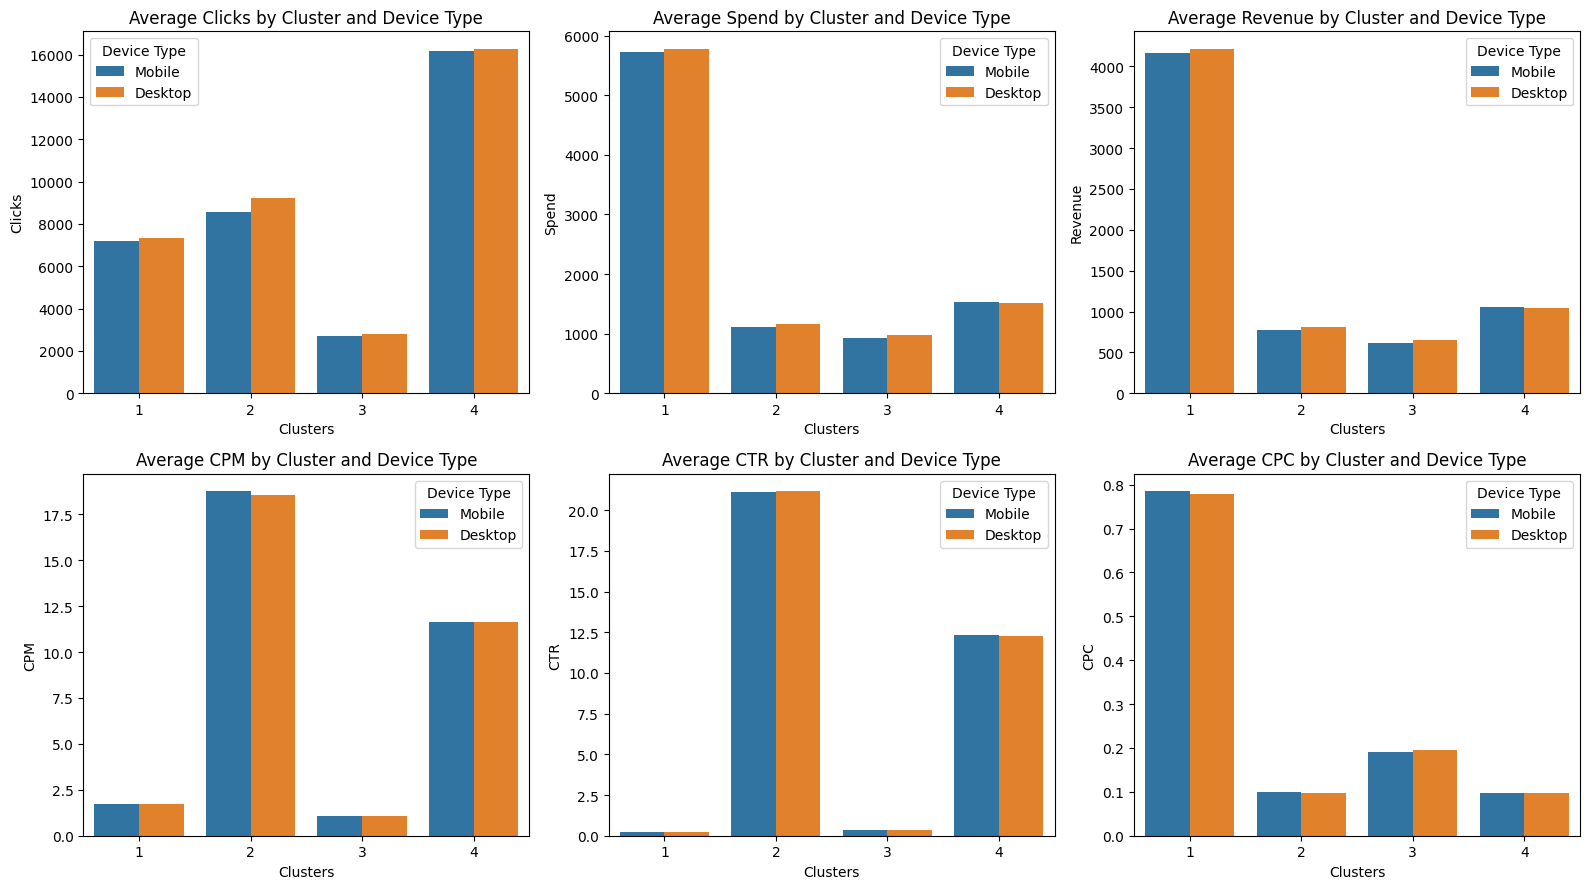

In [80]:
plt.figure(figsize=(16, 9))
for i, col in enumerate(metrics):
    plt.subplot(2, 3, i + 1)
    sns.barplot(x='Clusters', y=col, hue='Device Type', data=df, errorbar=None)
    plt.title('Average ' + col + ' by Cluster and Device Type')
plt.tight_layout()
plt.show()

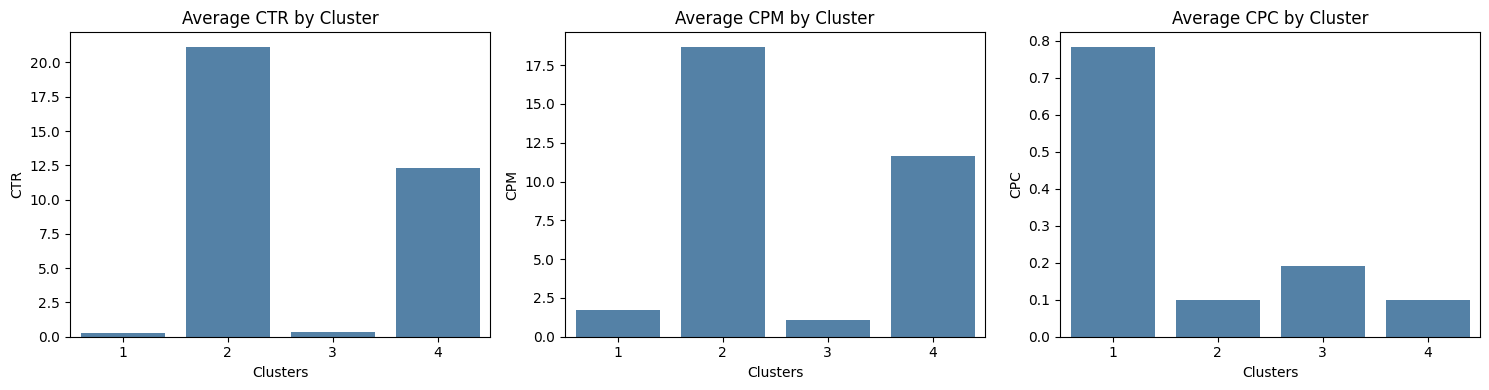

In [81]:
#Bar plot of the average of each clustering variable

plt.figure(figsize=(15, 4))
for i, col in enumerate(['CTR', 'CPM', 'CPC']):
    plt.subplot(1, 3, i + 1)
    sns.barplot(x='Clusters', y=col, data=df_clust, color='steelblue')
    plt.title('Average ' + col + ' by Cluster')
plt.tight_layout()
plt.show()

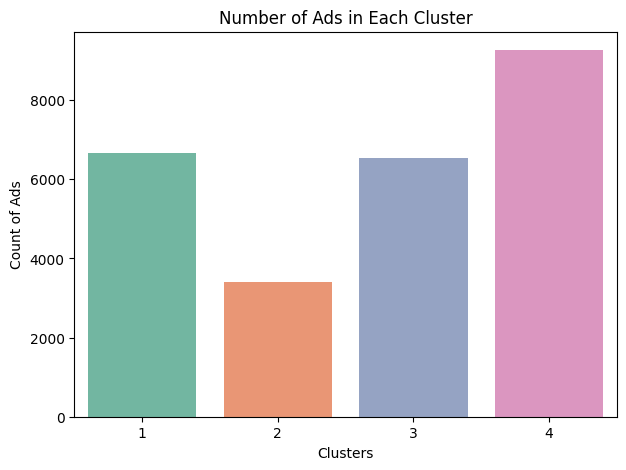

In [82]:
#Number of ads in each cluster

plt.figure(figsize=(7, 5))
sns.countplot(x='Clusters', data=df, palette='Set2')
plt.title('Number of Ads in Each Cluster')
plt.ylabel('Count of Ads')
plt.show()

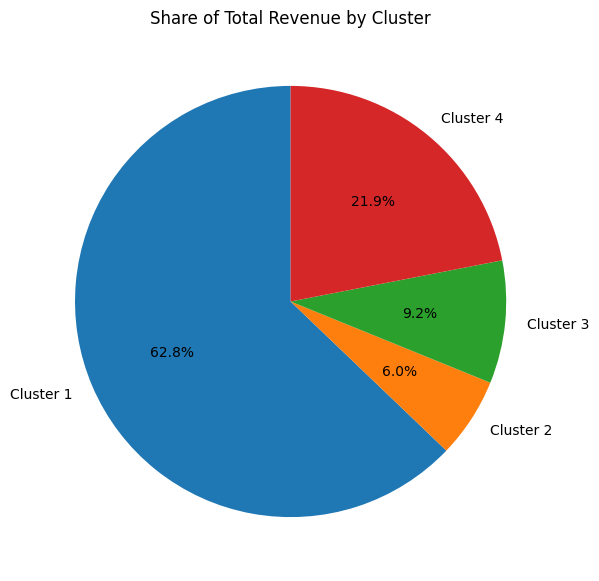

In [83]:
#Share of total revenue by cluster

plt.figure(figsize=(7, 7))
plt.pie(df.groupby('Clusters')['Revenue'].sum(),
        labels=['Cluster 1', 'Cluster 2', 'Cluster 3', 'Cluster 4'],
        autopct='%1.1f%%',
        startangle=90)
plt.title('Share of Total Revenue by Cluster')
plt.show()

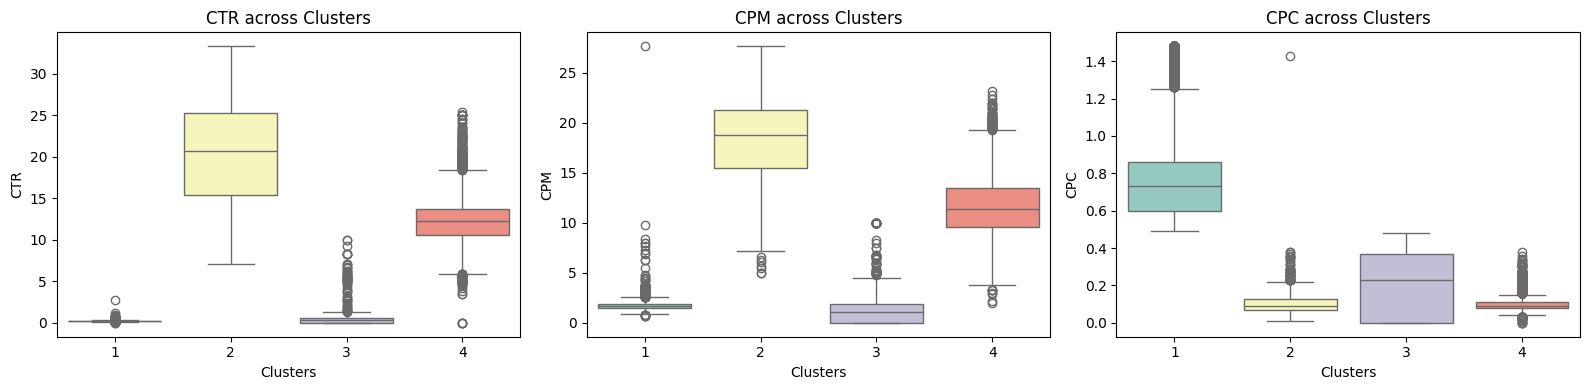

In [84]:
#Boxplots of the clustering variables across the clusters

plt.figure(figsize=(16, 4))
for i, col in enumerate(['CTR', 'CPM', 'CPC']):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(x='Clusters', y=col, data=df, palette='Set3')
    plt.title(col + ' across Clusters')
plt.tight_layout()
plt.show()

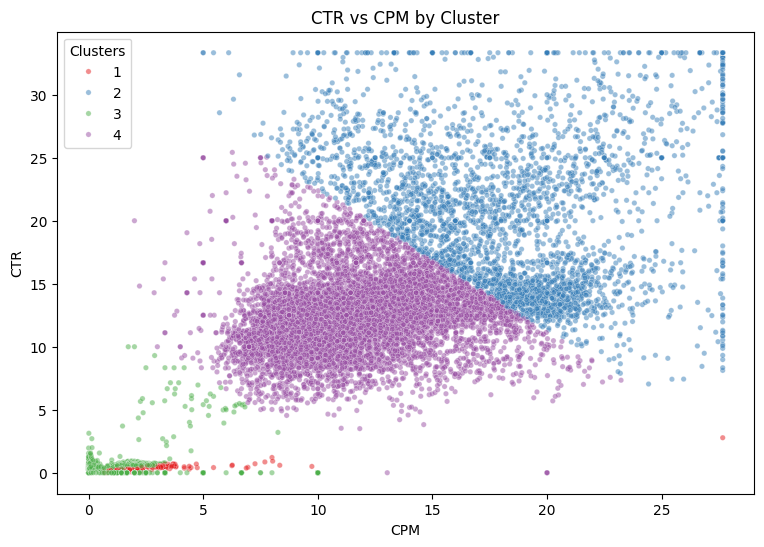

In [85]:
#Scatter plot of CTR against CPM coloured by cluster

plt.figure(figsize=(9, 6))
sns.scatterplot(x='CPM', y='CTR', hue='Clusters', data=df,
                palette='Set1', alpha=0.5, s=15)
plt.title('CTR vs CPM by Cluster')
plt.show()

In [86]:
#Heatmap of the scaled cluster centroids
#This shows at a glance which variable is high and which is low in each cluster.

centroids = pd.DataFrame(k_means.cluster_centers_, columns=['CTR', 'CPM', 'CPC'])
centroids.index = [1, 2, 3, 4]
centroids.index.name = 'Clusters'

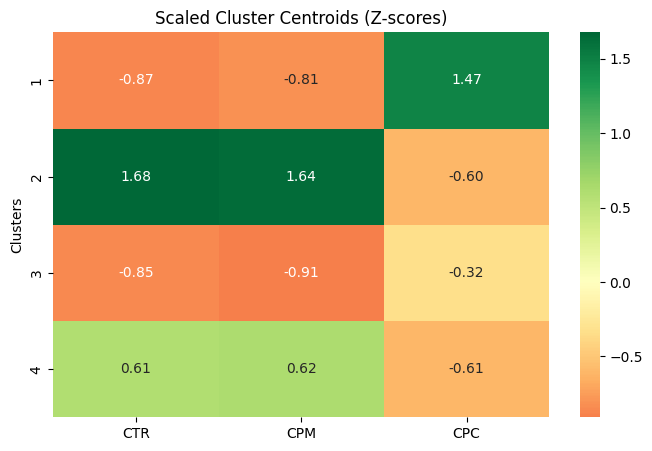

In [87]:
plt.figure(figsize=(8, 5))
sns.heatmap(centroids, annot=True, cmap='RdYlGn', center=0, fmt='.2f')
plt.title('Scaled Cluster Centroids (Z-scores)')
plt.show()

In [88]:
print(round(centroids, 3))

            CTR    CPM    CPC
Clusters                     
1        -0.865 -0.811  1.473
2         1.678  1.642 -0.605
3        -0.855 -0.908 -0.324
4         0.606  0.618 -0.609


## Step 13 : Comparing hierarchical and k-means


In [89]:
# Let us check how far the two methods actually agree with each other on the same
# 2000 records, so that we can justify which method we are finally going with.

from sklearn.metrics import adjusted_rand_score

In [90]:
sample_kmeans = df.loc[sample_index, 'Clusters'].values

In [91]:
# The cluster numbers themselves are arbitrary in both methods, so comparing the sizes
# side by side tells us nothing. We have to cross tabulate them instead.
print(pd.crosstab(pd.Series(clusters, name='Hierarchical'),
                  pd.Series(sample_kmeans, name='K-Means')))

K-Means         1    2    3    4
Hierarchical                    
1               0  143    0   29
2               0  116    7  714
3             328    0    0    0
4             181    0  482    0


In [92]:
print('Adjusted Rand Index :', round(adjusted_rand_score(clusters, sample_kmeans), 4))

# FINDING : The Adjusted Rand Index is 0.67 and once the arbitrary cluster numbers are
# matched up, the two methods put 83.4% of the sampled records in the same group. So they
# agree on the broad shape of the data but not on every record, and the disagreement sits
# mostly on the records lying near the cluster boundaries. That level of agreement is
# enough to say the 4 cluster structure is real and not an artefact of one algorithm.

# We report K-Means as the final answer because it runs on all 25857 records, whereas
# hierarchical clustering had to be run on a sample of 2000 for memory reasons.

Adjusted Rand Index : 0.6664


## END OF CODE
